# Flavour classifier benchmarks

The $\nu_\mu$ vs $\nu_e$ / $\nu_\tau$ classifier on its held-out test parquets. Events are drawn as in
training: flat in $(\log_{10} E_\nu, \cos\theta)$ over the bins every flavour populates, 50% $\nu_\mu$ and
25% each of $\nu_e$ and $\nu_\tau$, every event in its own random sub-geometry of the 1378-string grid.
$P(\nu_\mu)$ is at that 50% prior; `clf.predict_proba(..., signal_prior=p)` moves it to another.

In [1]:
import pickle
import time

import matplotlib.pyplot as plt
import numpy as np
import torch
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D
from sklearn.metrics import roc_auc_score, roc_curve
from torch.utils.data import BatchSampler, DataLoader, SequentialSampler

from nugget.losses.flavor_classifier import FlavorClassifier, FlavorDataset
from nugget.surrogates.FlowMatchLY import _reseed_dataset_rng_in_worker
from nugget.surrogates.FlowMatchReco import FEATURE_SETS, DetectorGeometry, pad_events

COLORS = {'mu': '#2a78d6', 'e': '#eb6834', 'tau': '#1baf7a', 'all': '#52514e'}
LABELS = {'mu': r'$\nu_\mu$', 'e': r'$\nu_e$', 'tau': r'$\nu_\tau$', 'all': 'all backgrounds'}
PLAIN = {'mu': 'nu_mu', 'e': 'nu_e', 'tau': 'nu_tau', 'all': 'all backgrounds'}
INK, MUTED, GRID, SURFACE = '#0b0b0b', '#898781', '#e1e0d9', '#fcfcfb'
TIME_CMAP = LinearSegmentedColormap.from_list(
    'time', ['#86b6ef', '#5598e7', '#2a78d6', '#1c5cab', '#104281', '#0d366b'])
plt.rcParams.update({
    'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'savefig.facecolor': SURFACE,
    'axes.edgecolor': '#c3c2b7', 'axes.labelcolor': INK, 'text.color': INK,
    'xtick.color': '#52514e', 'ytick.color': '#52514e', 'axes.grid': True,
    'grid.color': GRID, 'grid.linewidth': 0.6, 'axes.spines.top': False,
    'axes.spines.right': False, 'lines.linewidth': 2.0, 'legend.frameon': False,
})

In [2]:
TAG = 'mu_vs_e_tau_v1'
GEOM = '../other/800_40_40_geom.csv'
CHECKPOINT = f'./flavor_models/best_flavor_clf_{TAG}.pt'
HISTORY = f'./flavor_models/flavor_clf_{TAG}_training_history.pkl'
TEST_PARQUETS = {k: f'./flavor_models/flavor_clf_{TAG}_test_{k}.parquet' for k in ('mu', 'e', 'tau')}

DEVICE = 'cuda:3'
BATCH_SIZE = 128
NUM_WORKERS = 8
N_REF = 30_000      # events in the reference benchmark
N_SWEEP = 6_000     # events per point of the detector-size and OM-dropout sweeps

In [3]:
clf = FlavorClassifier(device=DEVICE, amp=True).load_model(CHECKPOINT)
clf.net.eval()
cfg = clf.data_config
BACKGROUNDS = [n for n in cfg['sources'] if n not in cfg['signal']]
TRAIN_GEOMETRY = {k: cfg[k] for k in ('n_strings_range', 'om_drop_prob', 'om_drop_range')}
print(f"silent tokens {cfg['silent_tokens']}, max_tokens {cfg['max_tokens']}, "
      f"training sub-geometry {TRAIN_GEOMETRY}")

FlavorClassifier: thesis features, encoder d_model=96 depth=10 (1,509,830 params), head width=256 depth=2 (131,841 params)
silent tokens strings, max_tokens 20000, training sub-geometry {'n_strings_range': (50, 300), 'om_drop_prob': 0.2, 'om_drop_range': (0.0, 0.5)}


## Training history

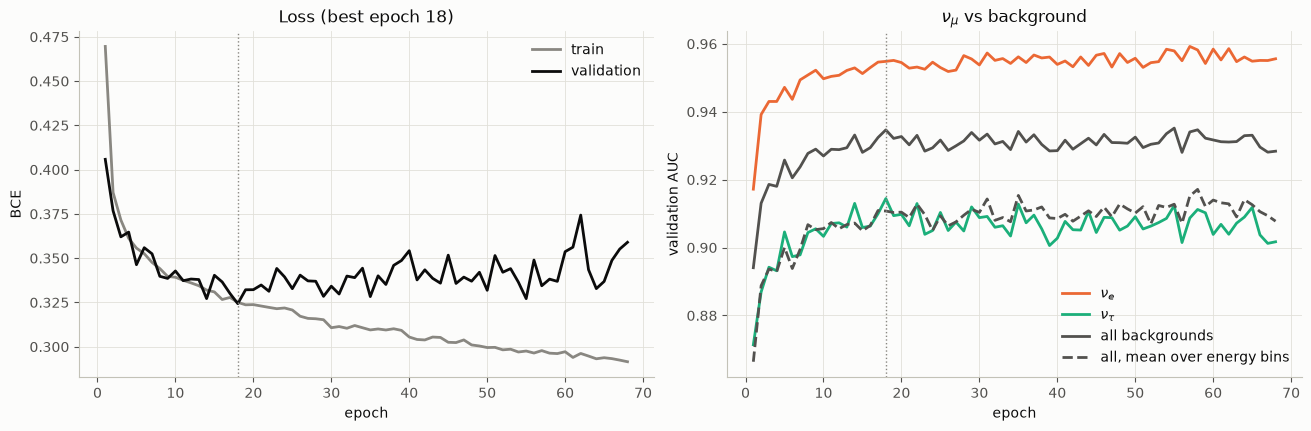

In [4]:
history = pickle.load(open(HISTORY, 'rb'))
ep = np.array([m['epoch'] for m in history['metrics']])
best = ep[int(np.argmin(history['val_loss']))]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), constrained_layout=True)
ax = axes[0]
ax.plot(ep, history['train_loss'], color=MUTED, label='train')
ax.plot(ep, history['val_loss'], color=INK, label='validation')
ax.set(xlabel='epoch', ylabel='BCE', title=f'Loss (best epoch {best})')
ax = axes[1]
for k in BACKGROUNDS + ['all']:
    key = 'auc' if k == 'all' else f'auc_{k}'
    ax.plot(ep, [m[key] for m in history['metrics']], color=COLORS[k], label=LABELS[k])
ax.plot(ep, [m['macro_auc'] for m in history['metrics']], color=COLORS['all'], ls='--',
        label='all, mean over energy bins')
ax.set(xlabel='epoch', ylabel='validation AUC', title=r'$\nu_\mu$ vs background')
for ax in axes:
    ax.axvline(best, color=MUTED, lw=1, ls=':')
    ax.legend()
plt.show()

## Test set

In [5]:
geo = DetectorGeometry.from_csv(GEOM)
reco_kw = {k: cfg[k] for k in ('energy_column', 'use_pulses', 'pulse_params', 'require_trigger',
                               'trigger_window', 'trigger_min_pmts', 'max_tokens',
                               'feature_set', 'silent_tokens')}
ds = FlavorDataset(TEST_PARQUETS, cfg['signal'], geo, seed=0, signal_frac=cfg['signal_frac'],
                   source_weights=cfg['source_weights'],
                   uniform_energy_zenith=cfg['uniform_energy_zenith'], **TRAIN_GEOMETRY, **reco_kw)
NAMES = ds.names

FlavorDataset [mu] (signal)
RecoFlowDataset: 48,669 events, 5,001,946 hit-PMT rows, 40,073,360 photons, 48,669 events/epoch
  hit PMTs/event: median 41, p99 1209, max 6078; log10 E in [2.00, 6.00]
  pulses=on, trigger=off, features=thesis, silent tokens=strings, max_tokens=20000
  geometry: 1378 strings; per event (50, 300) random strings, OM dropout (0.0, 0.5) with prob 0.2
FlavorDataset [e] (background)
RecoFlowDataset: 20,000 events, 2,033,545 hit-PMT rows, 57,555,599 photons, 20,000 events/epoch
  hit PMTs/event: median 31, p99 1299, max 2863; log10 E in [2.00, 6.00]
  pulses=on, trigger=off, features=thesis, silent tokens=strings, max_tokens=20000
  geometry: 1378 strings; per event (50, 300) random strings, OM dropout (0.0, 0.5) with prob 0.2
FlavorDataset [tau] (background)
RecoFlowDataset: 20,000 events, 1,744,623 hit-PMT rows, 48,189,406 photons, 20,000 events/epoch
  hit PMTs/event: median 25, p99 1195, max 4306; log10 E in [2.00, 6.00]
  pulses=on, trigger=off, features=thes

In [6]:
def set_geometry(n_strings_range=None, om_drop_prob=0.0, om_drop_range=(0.0, 0.0)):
    """Sub-geometry each test event is drawn in; n_strings_range None = all strings."""
    for s in ds.sources:
        s.masking = dict(n_strings_range=n_strings_range, om_drop_prob=om_drop_prob,
                         om_drop_range=om_drop_range)


def predict(n_events, seed=0, **geometry):
    """clf.predict_dataloader over n_events test draws in `geometry`, plus cos zenith and P(nu_mu)."""
    set_geometry(**geometry)
    ds.num_samples_per_epoch = int(n_events)
    ds._rng = np.random.default_rng(seed)
    # fresh, non-persistent workers, so each one sees the masking set above
    loader = DataLoader(ds, batch_size=None, num_workers=NUM_WORKERS,
                        sampler=BatchSampler(SequentialSampler(ds), BATCH_SIZE, drop_last=False),
                        worker_init_fn=_reseed_dataset_rng_in_worker,
                        generator=torch.Generator().manual_seed(seed))
    r = clf.predict_dataloader(loader)
    r['cos_zenith'] = np.empty(len(r['event']))
    for k, src in enumerate(ds.sources):
        m = r['source'] == k
        r['cos_zenith'][m] = np.cos(src._zenith[r['event'][m]])
    r['p_mu'] = 1.0 / (1.0 + np.exp(-r['logit'].astype(np.float64)))
    return r


def selections(r):
    """nu_mu against each background source, and against all of them."""
    sig = r['label'] > 0.5
    out = {n: sig | (r['source'] == NAMES.index(n)) for n in BACKGROUNDS}
    out['all'] = np.ones(len(sig), dtype=bool)
    return out


def auc_err(sig, z):
    """ROC AUC and its Hanley-McNeil standard error (nan without both classes)."""
    n1, n0 = int(sig.sum()), int((~sig).sum())
    if n1 == 0 or n0 == 0:
        return np.nan, np.nan
    a = roc_auc_score(sig, z)
    q1, q2 = a / (2 - a), 2 * a * a / (1 + a)
    return a, np.sqrt((a * (1 - a) + (n1 - 1) * (q1 - a * a) + (n0 - 1) * (q2 - a * a))
                      / (n1 * n0))


def eff_at(sig, z, bkg_acc):
    """nu_mu efficiency at the cut that keeps a bkg_acc fraction of the background."""
    return float((z[sig] > np.quantile(z[~sig], 1.0 - bkg_acc)).mean())


def summary(r):
    """AUC and the nu_mu efficiency at 10% / 1% background acceptance, per selection."""
    out = {}
    for k, m in selections(r).items():
        sig, z = r['label'][m] > 0.5, r['logit'][m]
        a, da = auc_err(sig, z)
        out[k] = dict(auc=a, auc_err=da, eff10=eff_at(sig, z, 0.1), eff1=eff_at(sig, z, 0.01))
    return out


def binned_auc(r, x, edges, min_per_class=30):
    """(n_bins, 2) AUC and error per selection in bins of x; nan where a class is thin."""
    b = np.clip(np.digitize(x, edges) - 1, 0, len(edges) - 2)
    out = {}
    for k, m in selections(r).items():
        v = np.full((len(edges) - 1, 2), np.nan)
        for i in range(len(edges) - 1):
            sel = m & (b == i)
            sig = r['label'][sel] > 0.5
            if sig.sum() >= min_per_class and (~sig).sum() >= min_per_class:
                v[i] = auc_err(sig, r['logit'][sel])
        out[k] = v
    return out

## Event display

A random test event of each flavour, each in its own random sub-geometry of the full grid. Top: plan
view, every string in light grey and the active ones darker. Bottom: side view onto the vertical plane
through the true $\nu$ axis. Marker area grows with charge (summed over the PMTs of an OM, and over the
OMs of a string in the plan view), colour is the earliest first-pulse time. $P(\nu_\mu)$ is the
classifier's at the training prior. The figure is also saved under `./plots/`.

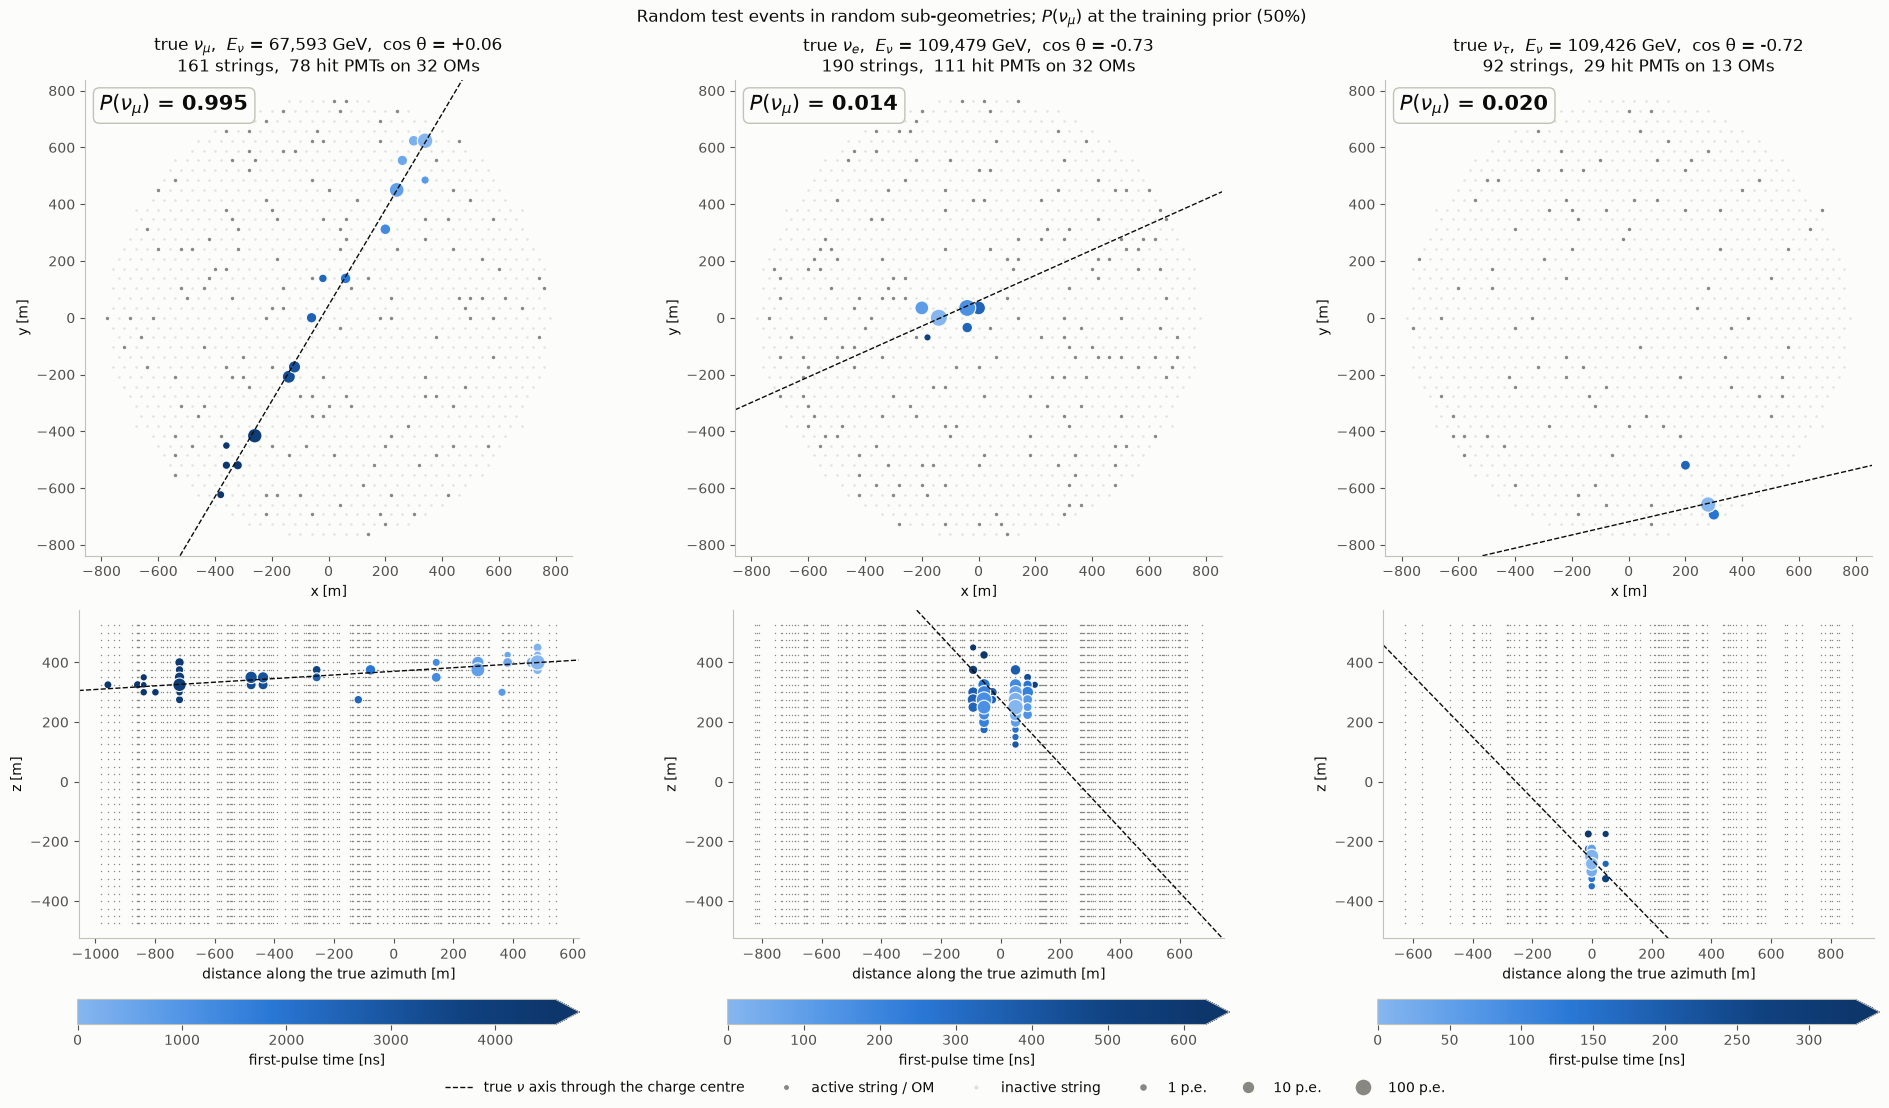

In [14]:
DISPLAY_SEED = None       # an int reproduces a draw
DISPLAY_GEOMETRY = dict(n_strings_range=TRAIN_GEOMETRY['n_strings_range'], om_drop_prob=0.0,
                        om_drop_range=(0.0, 0.0))
SHARED_GEOMETRY = False   # True: the three flavours in one sub-geometry
MIN_HIT_PMTS = 10         # redraw dimmer events (biases the display towards bright ones)

cols = FEATURE_SETS[clf.feature_set]['columns']
XYZ = [cols.index(c) for c in ('x', 'y', 'z')]
DXYZ = [cols.index(c) for c in ('dx', 'dy', 'dz')]
Q, T, HIT = (cols.index(c) for c in ('q_tot', 't_first', 'hit'))


def draw_event(k, active, rng, tries=10_000):
    """Event index and tokens of a random event of source k with >= MIN_HIT_PMTS hit PMTs in `active`."""
    ds._rng = rng
    for _ in range(tries):
        e = int(ds._sample_events(k, 1)[0])
        out = ds.sources[k].tokens(e, om_active=active)
        if out is not None and out[1][0] >= MIN_HIT_PMTS:
            return e, out
    raise RuntimeError(f"no [{NAMES[k]}] event with >= {MIN_HIT_PMTS} hit PMTs in {tries} draws")


def per_group(keys, q, t):
    """Unique rows of keys with their summed charge and earliest time."""
    u, inv = np.unique(keys, axis=0, return_inverse=True)
    inv = inv.reshape(-1)
    t_min = np.full(len(u), np.inf)
    np.minimum.at(t_min, inv, t)
    return u, np.bincount(inv, q, len(u)), t_min


def size(q):
    return 12.0 + 30.0 * np.log1p(q)


rng = np.random.default_rng(DISPLAY_SEED)
shared = geo.sample_active(rng, **DISPLAY_GEOMETRY) if SHARED_GEOMETRY else None
fig, axes = plt.subplots(2, len(NAMES), figsize=(6.5 * len(NAMES), 11), height_ratios=(1.45, 1),
                         constrained_layout=True)
for k, name in enumerate(NAMES):
    active = shared if shared is not None else geo.sample_active(rng, **DISPLAY_GEOMETRY)
    e, (f, g) = draw_event(k, active, rng)
    p_mu = clf.predict_proba(*pad_events([(f, g)])).item()
    src = ds.sources[k]
    zen, azi = float(src._zenith[e]), float(src._azimuth[e])
    h = f[f[:, HIT] > 0.5]
    center = (h[0, XYZ] - h[0, DXYZ]).astype(np.float64)
    om_xyz, om_q, om_t = per_group(h[:, XYZ], h[:, Q], h[:, T])
    st_xy, st_q, st_t = per_group(om_xyz[:, :2], om_q, om_t)
    t_max = max(float(np.percentile(om_t, 95)), 1.0)
    act_str = np.unique(geo.om_string[active])
    style = dict(cmap=TIME_CMAP, vmin=0.0, vmax=t_max, edgecolors=SURFACE, linewidths=0.8)

    ax = axes[0, k]
    ax.scatter(*geo.str_xy.T, s=3, color=GRID, lw=0)
    ax.scatter(*geo.str_xy[act_str].T, s=6, color=MUTED, lw=0)
    o = np.argsort(-st_t)   # earliest on top
    ax.scatter(st_xy[o, 0], st_xy[o, 1], s=size(st_q[o]), c=st_t[o], **style)
    ax.axline(center[:2], center[:2] + [np.cos(azi), np.sin(azi)], color=INK, lw=1, ls='--')
    ax.set(aspect='equal', xlabel='x [m]', ylabel='y [m]',
           title=f"true {LABELS[name]},  $E_\\nu$ = {10.0 ** src._log10e[e]:,.0f} GeV,  "
                 f"cos θ = {np.cos(zen):+.2f}\n"
                 f"{len(act_str)} strings,  {len(h)} hit PMTs on {len(om_xyz)} OMs")
    ax.text(0.03, 0.97, f"$P(\\nu_\\mu)$ = {p_mu:.3f}", transform=ax.transAxes, va='top',
            fontsize=15, fontweight='bold', bbox=dict(boxstyle='round', fc=SURFACE, ec='#c3c2b7'))
    ax.grid(False)

    ax = axes[1, k]
    u = np.array([np.cos(azi), np.sin(azi)])
    act_xyz = geo.om_pos[active]
    ax.scatter((act_xyz[:, :2] - center[:2]) @ u, act_xyz[:, 2], s=1, color=MUTED, lw=0)
    o = np.argsort(-om_t)
    sc = ax.scatter((om_xyz[o, :2] - center[:2]) @ u, om_xyz[o, 2], s=size(om_q[o]), c=om_t[o],
                    **style)
    ax.axline((0.0, center[2]), (np.sin(zen), center[2] + np.cos(zen)), color=INK, lw=1, ls='--')
    ax.set(aspect='equal', xlabel='distance along the true azimuth [m]', ylabel='z [m]')
    ax.grid(False)
    fig.colorbar(sc, ax=ax, orientation='horizontal', label='first-pulse time [ns]',
                 extend='max', shrink=0.8)

handles = [Line2D([], [], color=INK, lw=1, ls='--', label=r'true $\nu$ axis through the charge centre'),
           Line2D([], [], ls='', marker='o', ms=2.5, color=MUTED, label='active string / OM'),
           Line2D([], [], ls='', marker='o', ms=2, color=GRID, label='inactive string')]
handles += [Line2D([], [], ls='', marker='o', ms=np.sqrt(size(q)), color=MUTED, mec=SURFACE,
                   label=f'{q:g} p.e.') for q in (1, 10, 100)]
fig.legend(handles=handles, loc='outside lower center', ncol=len(handles))
fig.suptitle(r'Random test events in random sub-geometries; $P(\nu_\mu)$ at the training prior (50%)')
fig.savefig(f'./plots/flavor_event_display_{TAG}.png', dpi=150)
plt.show()

## Reference: the training sub-geometries

Every event in its own random sub-geometry drawn exactly as in training.

In [8]:
r_ref = predict(N_REF, seed=1, **TRAIN_GEOMETRY)
sig = r_ref['label'] > 0.5
z = r_ref['logit'].astype(np.float64)
print(f"{len(sig):,} events ({sig.sum():,} nu_mu)   BCE {np.mean(np.logaddexp(0.0, z) - sig * z):.4f}   "
      f"accuracy {np.mean((z > 0) == sig):.4f}\n")
print(f"{'nu_mu vs':16s} {'AUC':>16s} {'eff @ 10% bkg':>14s} {'eff @ 1% bkg':>13s}")
for k, s in summary(r_ref).items():
    print(f"{PLAIN[k]:16s} {s['auc']:9.4f} ± {s['auc_err']:.4f} {s['eff10']:14.3f} {s['eff1']:13.3f}")

30,000 events (15,108 nu_mu)   BCE 0.3339   accuracy 0.8428

nu_mu vs                      AUC  eff @ 10% bkg  eff @ 1% bkg
nu_e                0.9530 ± 0.0013          0.840         0.667
nu_tau              0.9096 ± 0.0019          0.724         0.253
all backgrounds     0.9312 ± 0.0015          0.780         0.416


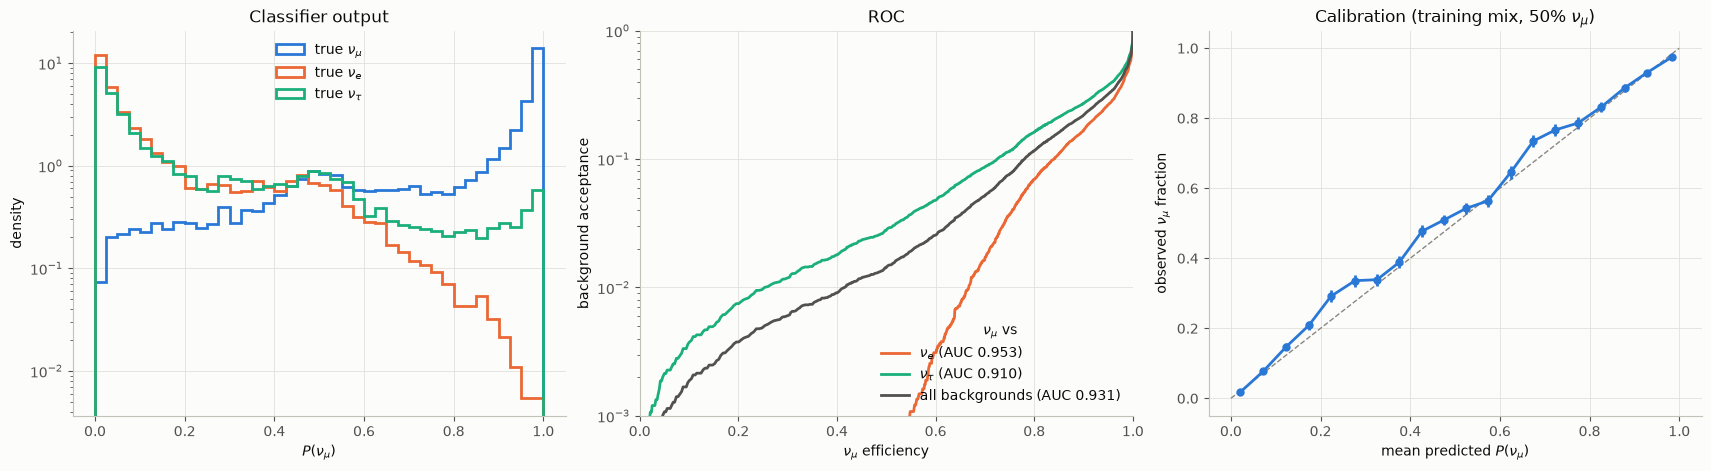

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6), constrained_layout=True)

ax = axes[0]
bins = np.linspace(0.0, 1.0, 41)
for k, n in enumerate(NAMES):
    ax.hist(r_ref['p_mu'][r_ref['source'] == k], bins=bins, density=True, histtype='step', lw=2,
            color=COLORS[n], label=f'true {LABELS[n]}')
ax.set(yscale='log', xlabel=r'$P(\nu_\mu)$', ylabel='density', title='Classifier output')
ax.legend(loc='upper center')

ax = axes[1]
for k, m in selections(r_ref).items():
    s = r_ref['label'][m] > 0.5
    fpr, tpr, _ = roc_curve(s, r_ref['logit'][m])
    ax.plot(tpr, fpr, color=COLORS[k],
            label=f"{LABELS[k]} (AUC {roc_auc_score(s, r_ref['logit'][m]):.3f})")
ax.set(yscale='log', xlim=(0.0, 1.0), ylim=(1e-3, 1.0), xlabel=r'$\nu_\mu$ efficiency',
       ylabel='background acceptance', title='ROC')
ax.legend(title=r'$\nu_\mu$ vs', loc='lower right')

ax = axes[2]
edges = np.linspace(0.0, 1.0, 21)
b = np.clip(np.digitize(r_ref['p_mu'], edges) - 1, 0, len(edges) - 2)
n_b = np.bincount(b, minlength=len(edges) - 1)
ok = n_b >= 20
p_mean = np.bincount(b, r_ref['p_mu'], len(edges) - 1)[ok] / n_b[ok]
frac = np.bincount(b, sig.astype(np.float64), len(edges) - 1)[ok] / n_b[ok]
ax.plot([0.0, 1.0], [0.0, 1.0], color=MUTED, lw=1, ls='--')
ax.errorbar(p_mean, frac, yerr=np.sqrt(frac * (1.0 - frac) / n_b[ok]), color=COLORS['mu'],
            marker='o', ms=5)
ax.set(xlabel=r'mean predicted $P(\nu_\mu)$', ylabel=r'observed $\nu_\mu$ fraction',
       title=r'Calibration (training mix, 50% $\nu_\mu$)')
plt.show()

### AUC vs energy, direction and brightness

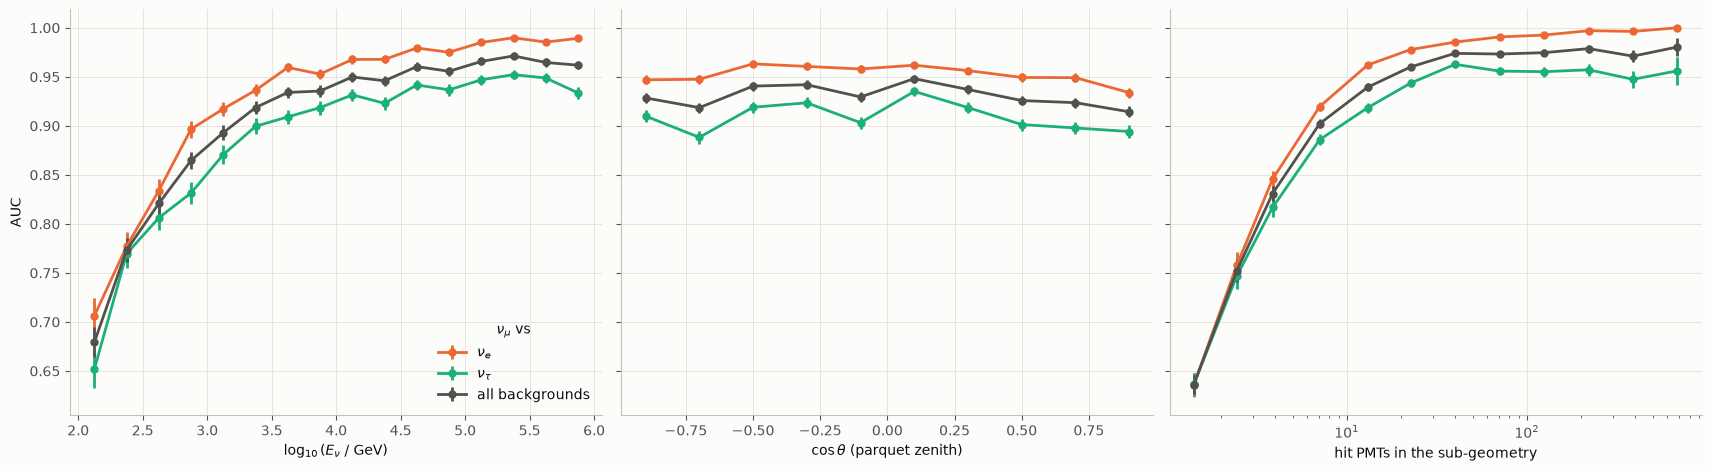

In [10]:
panels = [
    (r_ref['log10_energy'], np.linspace(2.0, 6.0, 17), r'$\log_{10}(E_\nu$ / GeV)', 'linear'),
    (r_ref['cos_zenith'], np.linspace(-1.0, 1.0, 11), r'$\cos\theta$ (parquet zenith)', 'linear'),
    (r_ref['n_pmt'], np.unique(np.geomspace(1, r_ref['n_pmt'].max() + 1, 14).round()),
     'hit PMTs in the sub-geometry', 'log'),
]
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6), sharey=True, constrained_layout=True)
for ax, (x, edges, label, scale) in zip(axes, panels):
    centers = (np.sqrt(edges[:-1] * edges[1:]) if scale == 'log'
               else 0.5 * (edges[:-1] + edges[1:]))
    for k, v in binned_auc(r_ref, x, edges).items():
        ax.errorbar(centers, v[:, 0], yerr=v[:, 1], color=COLORS[k], label=LABELS[k],
                    marker='o', ms=5)
    ax.set(xscale=scale, xlabel=label)
axes[0].set_ylabel('AUC')
axes[0].legend(title=r'$\nu_\mu$ vs', loc='lower right')
plt.show()

## Detector size and OM losses

Each point is `N_SWEEP` events, every one in its own random sub-geometry: exactly $n$ strings with all
their OMs, or 150 strings with a fixed fraction of the OMs dropped. Shaded: the range seen in training.

In [5]:
N_STRINGS = [25, 50, 100, 150, 200, 300, 500, 800, None]   # None = all strings
DROP_FRACS = [0.0, 0.1, 0.2, 0.3, 0.5, 0.7]
DROP_N_STRINGS = 150

t0 = time.time()
by_size = {n: summary(predict(N_SWEEP, seed=2, n_strings_range=None if n is None else (n, n)))
           for n in N_STRINGS}
by_drop = {f: summary(predict(N_SWEEP, seed=3, n_strings_range=(DROP_N_STRINGS,) * 2,
                              om_drop_prob=1.0 if f > 0 else 0.0, om_drop_range=(f, f)))
           for f in DROP_FRACS}
print(f"sweeps took {time.time() - t0:.0f} s")

NameError: name 'summary' is not defined

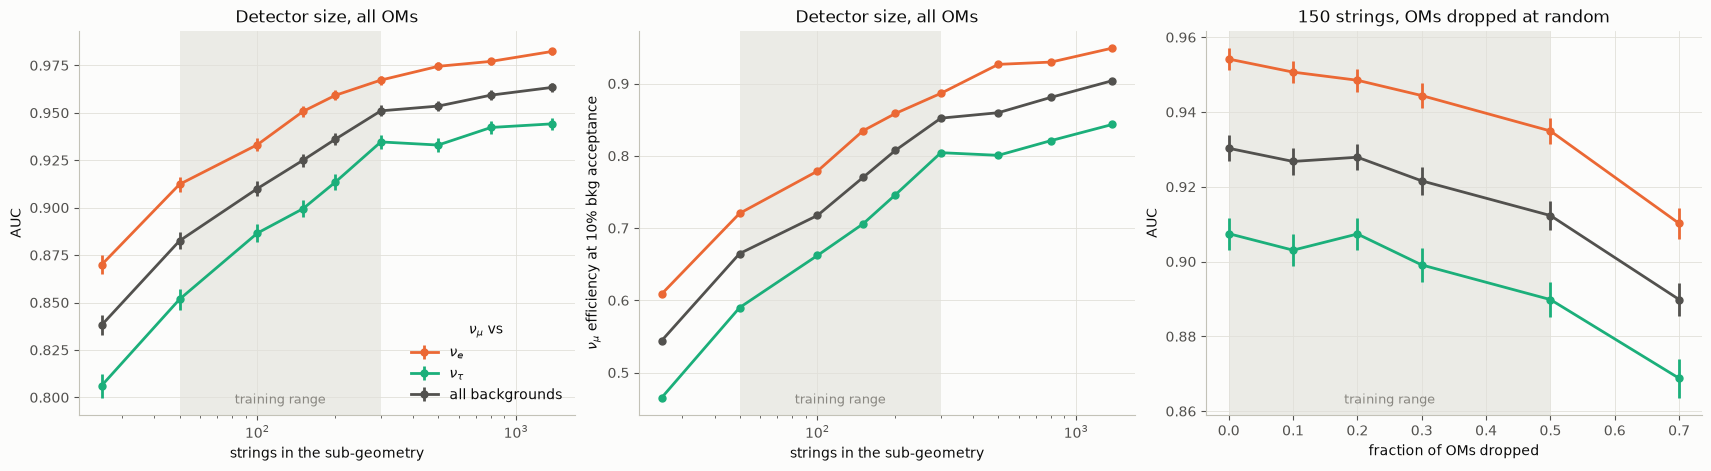

In [12]:
n_str = np.array([geo.n_strings if n is None else n for n in N_STRINGS])
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6), constrained_layout=True)
for k in BACKGROUNDS + ['all']:
    a = np.array([[by_size[n][k]['auc'], by_size[n][k]['auc_err']] for n in N_STRINGS])
    axes[0].errorbar(n_str, a[:, 0], yerr=a[:, 1], color=COLORS[k], label=LABELS[k],
                     marker='o', ms=5)
    axes[1].plot(n_str, [by_size[n][k]['eff10'] for n in N_STRINGS], color=COLORS[k],
                 label=LABELS[k], marker='o', ms=5)
    a = np.array([[by_drop[f][k]['auc'], by_drop[f][k]['auc_err']] for f in DROP_FRACS])
    axes[2].errorbar(DROP_FRACS, a[:, 0], yerr=a[:, 1], color=COLORS[k], label=LABELS[k],
                     marker='o', ms=5)

lo, hi = TRAIN_GEOMETRY['n_strings_range']
spans = [(axes[0], lo, hi, np.sqrt(lo * hi)), (axes[1], lo, hi, np.sqrt(lo * hi)),
         (axes[2], *TRAIN_GEOMETRY['om_drop_range'], np.mean(TRAIN_GEOMETRY['om_drop_range']))]
for ax, a, b, mid in spans:
    ax.axvspan(a, b, color=GRID, alpha=0.6, lw=0)
    ax.text(mid, 0.03, 'training range', transform=ax.get_xaxis_transform(), ha='center',
            color=MUTED, fontsize=9)
for ax in axes[:2]:
    ax.set(xscale='log', xlabel='strings in the sub-geometry')
axes[0].set(ylabel='AUC', title='Detector size, all OMs')
axes[1].set(ylabel=r'$\nu_\mu$ efficiency at 10% bkg acceptance', title='Detector size, all OMs')
axes[2].set(xlabel='fraction of OMs dropped', ylabel='AUC',
            title=f'{DROP_N_STRINGS} strings, OMs dropped at random')
axes[0].legend(title=r'$\nu_\mu$ vs', loc='lower right')
plt.show()

## Throughput

Model alone (encoder + head, no host-to-device copy) on training-like batches, and the CPU tokenisation
that feeds it (pulses, sub-geometry, silent tokens), which the DataLoader workers parallelise.

In [13]:
N_REPEAT = 20


def sync():
    if torch.device(DEVICE).type == 'cuda':
        torch.cuda.synchronize(DEVICE)


set_geometry(**TRAIN_GEOMETRY)
ds._rng = np.random.default_rng(4)
t0 = time.perf_counter()
batch = ds.get_batch(np.arange(512))
print(f"tokenisation, one CPU process: {512 / (time.perf_counter() - t0):,.0f} events/s")

with torch.no_grad():
    for bs in (32, 128, 512):
        m = batch[1][:bs]
        n = int(m.sum(1).max())
        f, m, g = clf._prep(batch[0][:bs, :n]), m[:, :n].to(DEVICE), clf._prep(batch[2][:bs])
        clf.logits(f, m, g)
        sync()
        t0 = time.perf_counter()
        for _ in range(N_REPEAT):
            clf.logits(f, m, g)
        sync()
        dt = (time.perf_counter() - t0) / N_REPEAT
        print(f"batch {bs:4d} ({n:5d} tokens after padding): {dt * 1e3:7.1f} ms, "
              f"{bs / dt:9,.0f} events/s")

tokenisation, one CPU process: 538 events/s
batch   32 ( 1621 tokens after padding):    24.2 ms,     1,320 events/s
batch  128 ( 1621 tokens after padding):    91.5 ms,     1,399 events/s
batch  512 ( 2308 tokens after padding):   653.0 ms,       784 events/s


## Surrogate

`FlavorSurrogate` predicts the classifier's expected $P(\nu_\mu)$ for a $\nu_\mu$ event in a geometry
from the event and the OM positions alone. Here it is compared with the classifier itself on $\nu_\mu$
test events (flat in $(\log_{10} E_\mu, \cos\theta)$, as in its training) in three kinds of random
geometry, each with as many strings as in training:

- **grid**: random strings of the dense grid with all their OMs, as in training. Here the classifier
  also runs on the parquet's own simulated response.
- **uniform**: strings anywhere in the grid's disc, off the grid but at least 40 m apart, each with the
  grid's 41 OM depths.
- **cluster**: the same, Gaussian around a random point (width 100–400 m): compact layouts neither
  model was trained on.

Off the grid the parquet has no response, so every event is re-simulated with NuSmoothie (hit,
light-yield and arrival-time flows), then goes through the same pulse simulation and tokens as in
training. The surrogate learned $E[P \mid \text{detected}]$, so every comparison uses detected events.
Black is the classifier (solid: parquet response, dashed: NuSmoothie response), violet the surrogate.

In [8]:
import pandas as pd

from nugget.losses.flavor_surrogate import ENERGY_COLUMNS, FlavorSurrogate
from nugget.losses.reco_gd import RecoGDLoss
from nugget.surrogates.FlowMatchATime import _ragged_indices
from nugget.surrogates.FlowMatchReco import (PulseSimulator, RecoFlowDataset, event_tokens,
                                             om_triggered)
from nugget.surrogates.NuSmoothie import NuSmoothie

SUR_CHECKPOINT = f'./flavor_models/best_flavor_surrogate_{TAG}_s1.pt'
SMOOTHIE = dict(hit_checkpoint='./flow_models/best_mc_muon_hit_model_v1rl.pt',
                ly_checkpoint='./flow_models/best_mc_ly_muon_flow_model_v1rl.pt',
                atime_checkpoint='./flow_models/best_mc_atime_muon_flow_model_v1rlg.pt')
SUR_STRINGS = TRAIN_GEOMETRY['n_strings_range']   # strings per random geometry
N_GEOMS = 40            # random geometries per layout kind
EVENTS_PER_GEOM = 32    # test events simulated in each
N_PAIRS = 60            # (geometry, event) pairs per kind in the repeated-response test
N_DRAWS = 16            # NuSmoothie responses per pair
SUR_COLOR = '#6250d6'

sur = FlavorSurrogate(device=DEVICE).load_model(SUR_CHECKPOINT)
sim = RecoGDLoss(device=DEVICE, geometry_csv_path=GEOM, response_n_steps=32,
                 response_events_per_batch=16, verbose=False, **SMOOTHIE)
E_SIM, E_SUR = sim.hit_model.energy_column, ENERGY_COLUMNS[sur.energy_type]
print(f"surrogate: {E_SUR}, learns undetected={sur.data_config['undetected']!r}, "
      f"{len(sur.metrics)} epochs; NuSmoothie flows: {E_SIM}")

FlavorSurrogate: muon energy, d_model=64, OM/string depth 4/4, head 256x4 (1,985,985 params)
HitClassifier: context_dim=11, width=256, depth=8, params=1,060,609
FlowMatchLY: context_dim=11, width=256, depth=8, params=2,441,729
FlowMatchLY: context_dim=11, width=256, depth=12, params=3,627,521
surrogate: muon_energy, learns undetected='redraw', 195 epochs; NuSmoothie flows: muon_energy


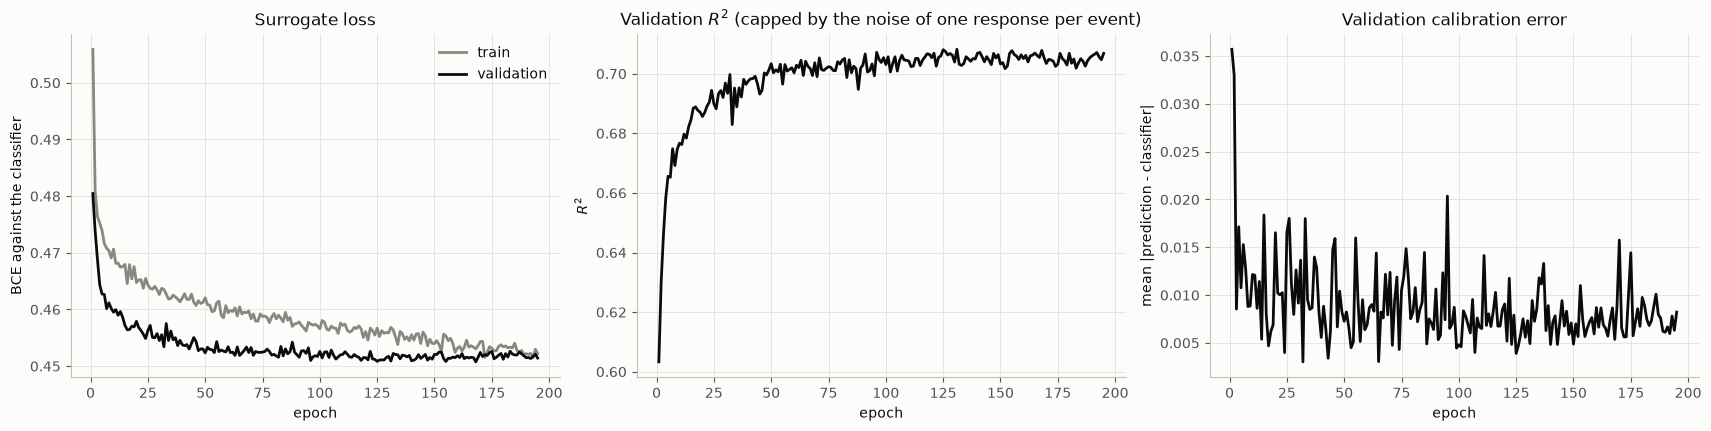

In [9]:
m = pd.DataFrame(sur.metrics)
fig, axes = plt.subplots(1, 3, figsize=(17, 4.2), constrained_layout=True)
ax = axes[0]
ax.plot(m.epoch, sur.train_losses[:len(m)], color=MUTED, label='train')
ax.plot(m.epoch, m.bce, color=INK, label='validation')
ax.set(xlabel='epoch', ylabel='BCE against the classifier', title='Surrogate loss')
ax.legend()
axes[1].plot(m.epoch, m.r2, color=INK)
axes[1].set(xlabel='epoch', ylabel=r'$R^2$',
            title=r'Validation $R^2$ (capped by the noise of one response per event)')
axes[2].plot(m.epoch, m.ece, color=INK)
axes[2].set(xlabel='epoch', ylabel='mean |prediction - classifier|',
            title='Validation calibration error')
plt.show()

In [10]:
# nu_mu test events with their vertex, flat in (log10 E_mu, cos zen) like the surrogate's training
mu = RecoFlowDataset(TEST_PARQUETS['mu'], geo, seed=0, uniform_energy_zenith=True, verbose=False,
                     event_columns=tuple(dict.fromkeys(('muon_x', 'muon_y', 'muon_z', E_SIM, E_SUR))),
                     **TRAIN_GEOMETRY, **{**reco_kw, 'energy_column': E_SUR})
VERTEX = np.stack([mu.event_columns[c] for c in ('muon_x', 'muon_y', 'muon_z')], axis=1)
TEMPLATE = NuSmoothie.pmt_directions_from_geometry(GEOM)
Z_LEVELS = geo.om_pos[geo.str_om_start[0] + np.arange(geo.str_om_count[0]), 2]
R_GRID = float(np.linalg.norm(geo.str_xy, axis=1).max())
MIN_SPACING = 40.0      # m, the grid's string spacing
pulses = PulseSimulator(**cfg['pulse_params']) if cfg['use_pulses'] else None


def grid_layout(n, rng):
    """OM positions of n random grid strings with all their OMs, and their mask over the grid."""
    act = np.isin(geo.om_string, rng.choice(geo.n_strings, n, replace=False))
    oms = np.flatnonzero(act)
    # string xy rather than the OM means, so the surrogate groups the strings exactly
    return np.column_stack([geo.str_xy[geo.om_string[oms]], geo.om_pos[oms, 2]]), act


def _in_disc(rng, radius):
    r, phi = radius * np.sqrt(rng.random()), 2.0 * np.pi * rng.random()
    return np.array([r * np.cos(phi), r * np.sin(phi)])


def free_layout(n, rng, cluster=False):
    """OM positions of n strings off the grid, >= MIN_SPACING apart in its disc, at its OM depths:
    uniform, or (cluster) Gaussian around a random point, width log-uniform in 100-400 m."""
    c, s = _in_disc(rng, R_GRID / 2), np.exp(rng.uniform(np.log(100.0), np.log(400.0)))
    xy, misses = np.empty((0, 2)), 0
    while len(xy) < n:
        p = c + s * rng.normal(size=2) if cluster else _in_disc(rng, R_GRID)
        if (np.linalg.norm(p) <= R_GRID
                and (len(xy) == 0 or np.linalg.norm(xy - p, axis=1).min() >= MIN_SPACING)):
            xy, misses = np.vstack([xy, p]), 0
        else:
            misses += 1
            if misses > 200:    # too tight for n strings: widen the cluster
                s, misses = 1.2 * s, 0
    return np.column_stack([np.repeat(xy, len(Z_LEVELS), axis=0), np.tile(Z_LEVELS, n)]), None


LAYOUTS = {'grid': grid_layout, 'uniform': free_layout,
           'cluster': lambda n, rng: free_layout(n, rng, cluster=True)}


def layout_geometry(pos):
    """DetectorGeometry of OMs pos with the 16-PMT template (strings by exact x, y; OMs numbered
    by z), and the PMT index of each of NuSmoothie's OM-major PMT rows."""
    _, string = np.unique(pos[:, :2], axis=0, return_inverse=True)
    string = string.reshape(-1)
    order = np.lexsort((pos[:, 2], string))
    om = np.empty(len(pos), dtype=np.int64)
    om[order] = np.arange(len(pos)) - np.searchsorted(string[order], string[order])
    K = len(TEMPLATE)
    s, o, k = np.repeat(string, K), np.repeat(om, K), np.tile(np.arange(K), len(pos))
    g = DetectorGeometry(s, o, k, np.repeat(pos, K, axis=0), np.tile(TEMPLATE, (len(pos), 1)))
    return g, g.lookup(s, o, k)


def response_tokens(resp, g, rows, rng):
    """Classifier tokens of each event of a NuSmoothie Response in g, built as RecoFlowDataset
    builds them from the parquet's photons (None: no pulse, or no trigger)."""
    out = [None] * len(resp.truth)
    for ev, h in resp.hits.groupby('ev'):
        n = h.n.to_numpy()
        tok = np.repeat(rows[h.pmt_idx.to_numpy()], n)
        t = resp.times[_ragged_indices(h.start.to_numpy(), n)].astype(np.float64)
        if pulses is None:
            q = np.ones_like(t)
        else:
            tok, t, q = pulses(tok, t, rng)
            if len(t) == 0:
                continue
        if cfg['require_trigger'] and not om_triggered(
                g.pmt_om[tok], g.pmt[tok], t, cfg['trigger_window'], cfg['trigger_min_pmts']):
            continue
        out[ev] = event_tokens(tok, t, q, g, cfg['max_tokens'], cfg['feature_set'],
                               cfg['silent_tokens'])
    return out


@torch.no_grad()
def classify(toks, batch=256):
    """Classifier P(nu_mu) of each token set; NaN for None."""
    p = np.full(len(toks), np.nan)
    idx = [i for i, t in enumerate(toks) if t is not None]
    for s in range(0, len(idx), batch):
        b = idx[s:s + batch]
        p[b] = clf.predict_proba(*pad_events([toks[i] for i in b])).float().cpu().numpy()
    return p


def nusmoothie_p(pos, evs, rng):
    """Classifier P(nu_mu) of one NuSmoothie response of each of events evs in OMs pos (NaN: no
    pulse). The truth keeps the parquet's angles, which are the flows' own convention."""
    truth = pd.DataFrame(dict(
        run_id=0, event_id=np.arange(len(evs)), x=VERTEX[evs, 0], y=VERTEX[evs, 1],
        z=VERTEX[evs, 2], zenith=mu._zenith[evs].astype(float),
        azimuth=mu._azimuth[evs].astype(float), energy=mu.event_columns[E_SIM][evs]))
    g, rows = layout_geometry(pos)
    resp = sim.simulate_response(pos, truth, seed=int(rng.integers(2 ** 31)))
    return classify(response_tokens(resp, g, rows, rng))


@torch.no_grad()
def surrogate_p(pos, evs):
    """Surrogate's expected P(nu_mu) of events evs in OMs pos."""
    # the parquet direction points back along the track; the surrogate takes the travel direction
    params = [dict(position=VERTEX[e], energy=mu.event_columns[E_SUR][e], direction=-mu._dir[e])
              for e in evs]
    return sur.predict_geometry(torch.as_tensor(pos), params).float().cpu().numpy()


def compare(kind, n_geoms, events_per_geom, seed):
    """One row per (geometry, event): the surrogate, the classifier on a NuSmoothie response and,
    on the grid, on the parquet's own response (NaN where a response has no pulse)."""
    rng = np.random.default_rng(seed)
    mu._rng = rng
    out = []
    for gi in range(n_geoms):
        n = int(rng.integers(SUR_STRINGS[0], SUR_STRINGS[1] + 1))
        pos, act = LAYOUTS[kind](n, rng)
        evs = mu._sample_events(events_per_geom)
        p_mc = (np.full(len(evs), np.nan) if act is None
                else classify([mu.tokens(e, om_active=act) for e in evs]))
        out.append(pd.DataFrame(dict(
            kind=kind, geometry=gi, n_strings=n, event=evs, log10_e=mu._log10e[evs],
            p_sur=surrogate_p(pos, evs), p_sim=nusmoothie_p(pos, evs, rng), p_mc=p_mc)))
    return pd.concat(out, ignore_index=True)


def calibration(p_sur, p_clf, n_bins=10):
    """Quantile bins of the surrogate's prediction: mean prediction, mean classifier P and its
    error per bin, and the count-weighted mean |difference| (NaN classifier values dropped)."""
    ok = np.isfinite(p_clf)
    if not ok.any():
        return np.empty(0), np.empty(0), np.empty(0), float('nan')
    x, y = p_sur[ok], p_clf[ok]
    b = np.clip(np.searchsorted(np.quantile(x, np.linspace(0.0, 1.0, n_bins + 1)), x,
                                side='right') - 1, 0, n_bins - 1)
    n = np.bincount(b, minlength=n_bins)
    keep = n > 0
    n = n[keep]
    mx, my = (np.bincount(b, v, n_bins)[keep] / n for v in (x, y))
    sem = np.sqrt(np.maximum(np.bincount(b, y * y, n_bins)[keep] / n - my ** 2, 0.0) / n)
    return mx, my, sem, float((np.abs(mx - my) * n).sum() / n.sum())


def binned_mean(x, y, edges, min_count=10):
    """Mean of the finite y in bins of x; NaN in bins with fewer than min_count."""
    ok = np.isfinite(y)
    b = np.clip(np.digitize(x[ok], edges) - 1, 0, len(edges) - 2)
    n = np.bincount(b, minlength=len(edges) - 1)
    m = np.bincount(b, y[ok], len(edges) - 1) / np.maximum(n, 1)
    return np.where(n >= min_count, m, np.nan)

### One event: parquet and NuSmoothie

A random $\nu_\mu$ test event in a random grid geometry (`SUR_STRINGS` strings, all OMs), redrawn
until its parquet response lights at least `SINGLE_MIN_HITS` PMTs. Left: the parquet's own
response. Right: a NuSmoothie response of the same event in the same OMs. Each panel gives the
classifier's $P(\nu_\mu)$ of that response and the surrogate's prediction, which needs no response
and so is the same in both. Dashed: the true track axis through the vertex (×). The table times
each step after a warm-up, for this event alone and per event in a batch of `SPEED_BATCH` events in
the same geometry. Uses the helpers of the event-display cell above.

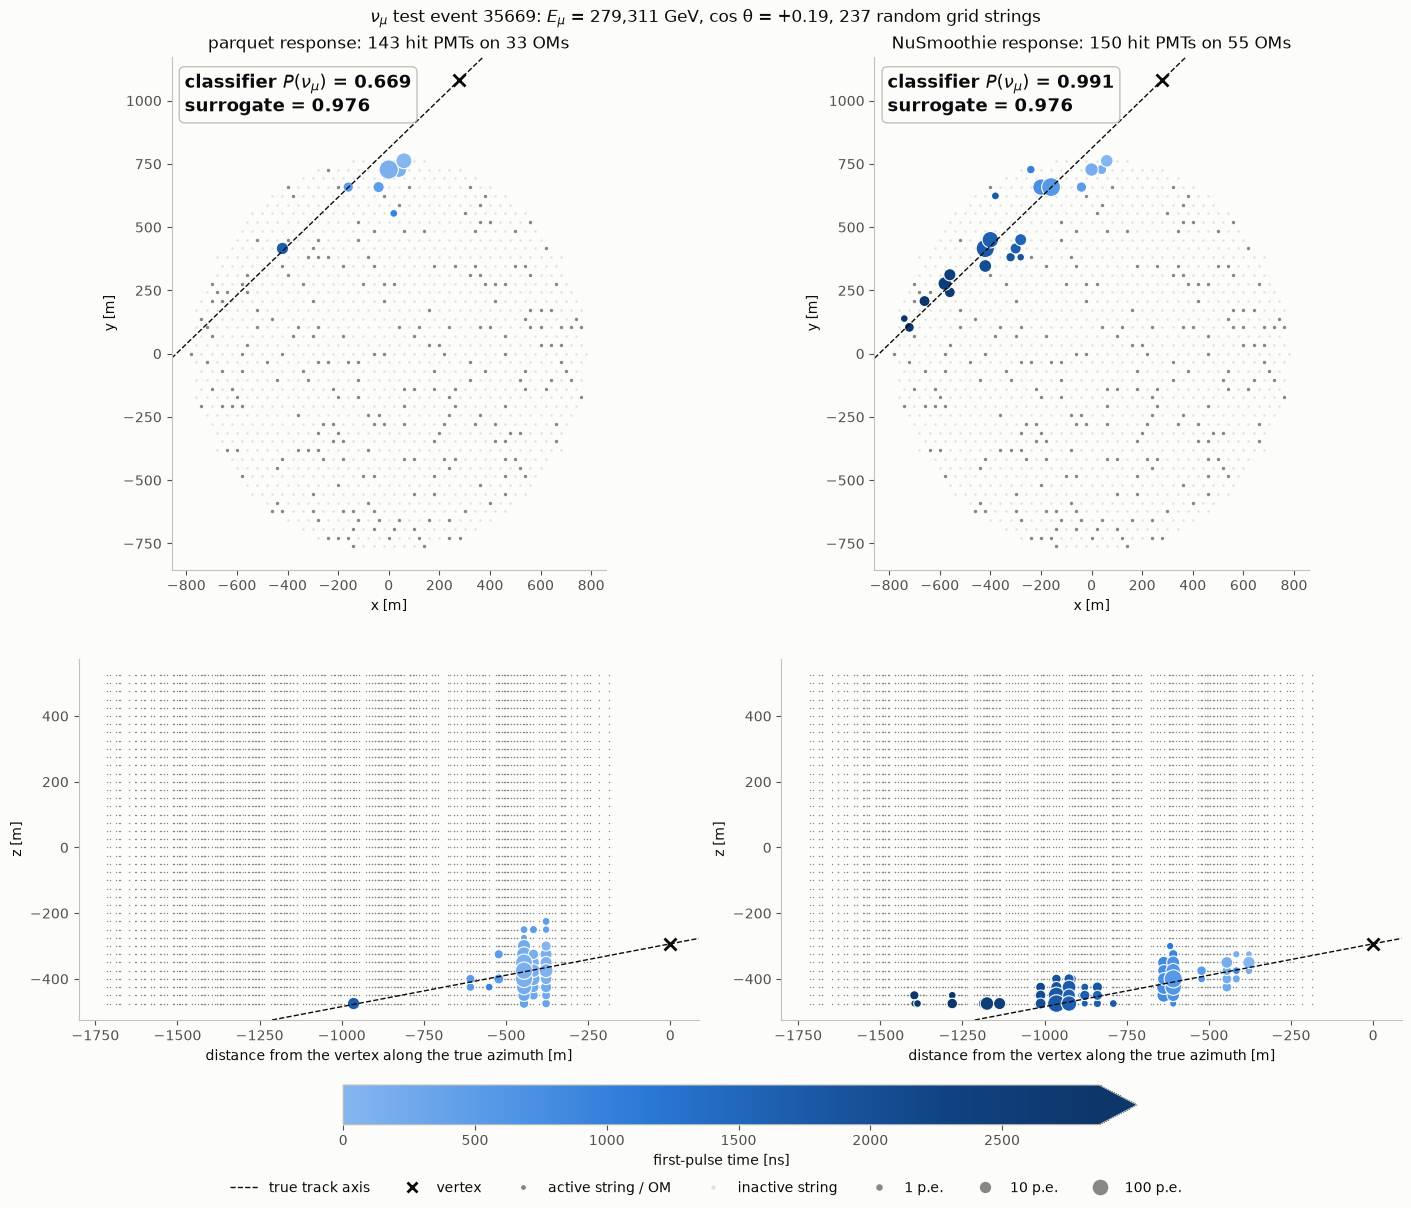

DetectorGeometry of the 237-string layout for NuSmoothie's tokens (once per geometry): 31.6 ms

                                              one event [ms]  per event, batch of 64 [ms]
parquet: tokens (pulses from its photons)              1.442                        1.103
parquet: classifier                                    7.025                        0.850
classifier total, parquet                              8.467                        1.953
NuSmoothie: response                                1207.953                       85.305
NuSmoothie: tokens                                     1.772                        0.856
NuSmoothie: classifier                                 7.076                        1.404
classifier total, NuSmoothie                        1216.802                       87.565
surrogate                                              6.797                        1.522
surrogate + gradient w.r.t. the OM positions          13.909                        2.637


In [32]:
SINGLE_SEED = None      # an int reproduces the draw
SINGLE_MIN_HITS = 20    # hit PMTs the parquet response needs
SPEED_REPEAT = 10       # timed calls per step after one warm-up (3 for the batch)
SPEED_BATCH = 64


def _sync():
    if torch.device(DEVICE).type == 'cuda':
        torch.cuda.synchronize(DEVICE)


def timed(fn, n_repeat=SPEED_REPEAT):
    """Mean wall time [ms] of fn() over n_repeat calls after a warm-up call, and its last result."""
    out = fn()
    _sync()
    t0 = time.perf_counter()
    for _ in range(n_repeat):
        out = fn()
    _sync()
    return 1e3 * (time.perf_counter() - t0) / n_repeat, out


def surrogate_grad(pos, evs):
    """Gradient of the surrogate's summed prediction w.r.t. the OM positions."""
    pts = torch.as_tensor(pos, device=DEVICE).requires_grad_(True)
    params = [dict(position=VERTEX[e], energy=mu.event_columns[E_SUR][e], direction=-mu._dir[e])
              for e in evs]
    return torch.autograd.grad(sur.predict_geometry(pts, params).sum(), pts)[0]


def time_steps(evs, n_repeat):
    """Wall time [ms] of each step for events evs in the geometry pos, and the last results."""
    truth = pd.DataFrame(dict(    # the parquet's angles are the flows' own convention
        run_id=0, event_id=np.arange(len(evs)), x=VERTEX[evs, 0], y=VERTEX[evs, 1],
        z=VERTEX[evs, 2], zenith=mu._zenith[evs].astype(float),
        azimuth=mu._azimuth[evs].astype(float), energy=mu.event_columns[E_SIM][evs]))
    t, out = {}, {}
    t['parquet: tokens (pulses from its photons)'], out['tok_mc'] = timed(
        lambda: [mu.tokens(x, om_active=act) for x in evs], n_repeat)
    t['parquet: classifier'], out['p_mc'] = timed(lambda: classify(out['tok_mc']), n_repeat)
    t['NuSmoothie: response'], resp = timed(
        lambda: sim.simulate_response(pos, truth, seed=int(rng.integers(2 ** 31))), n_repeat)
    t['NuSmoothie: tokens'], out['tok_sim'] = timed(
        lambda: response_tokens(resp, sim_geo, sim_rows, rng), n_repeat)
    t['NuSmoothie: classifier'], out['p_sim'] = timed(lambda: classify(out['tok_sim']), n_repeat)
    t['surrogate'], out['p_sur'] = timed(lambda: surrogate_p(pos, evs), n_repeat)
    t['surrogate + gradient w.r.t. the OM positions'] = timed(
        lambda: surrogate_grad(pos, evs), n_repeat)[0]
    return t, out


rng = np.random.default_rng(SINGLE_SEED)
mu._rng = rng
n_str = int(rng.integers(SUR_STRINGS[0], SUR_STRINGS[1] + 1))
pos, act = grid_layout(n_str, rng)
for _ in range(10_000):
    e = int(mu._sample_events(1)[0])
    tok = mu.tokens(e, om_active=act)
    if tok is not None and tok[1][0] >= SINGLE_MIN_HITS:
        break
else:
    raise RuntimeError(f"no event with >= {SINGLE_MIN_HITS} hit PMTs in 10,000 draws")
t_geo, (sim_geo, sim_rows) = timed(lambda: layout_geometry(pos))
t_one, one = time_steps(np.array([e]), SPEED_REPEAT)
t_batch, _ = time_steps(mu._sample_events(SPEED_BATCH), 3)

# ---- display ----
zen, azi, vtx = float(mu._zenith[e]), float(mu._azimuth[e]), VERTEX[e]
u = np.array([np.cos(azi), np.sin(azi)])
panels = []
for name, tok, p_clf in (('parquet response', one['tok_mc'][0], one['p_mc'][0]),
                         ('NuSmoothie response', one['tok_sim'][0], one['p_sim'][0])):
    hit = None
    if tok is not None:
        h = tok[0][tok[0][:, HIT] > 0.5]
        hit = per_group(h[:, XYZ], h[:, Q], h[:, T]), len(h)
    panels.append((name, hit, p_clf))
t_all = np.concatenate([h[0][2] for _, h, _ in panels if h is not None])
style = dict(cmap=TIME_CMAP, vmin=0.0, vmax=max(float(np.percentile(t_all, 95)), 1.0),
             edgecolors=SURFACE, linewidths=0.8)

fig, axes = plt.subplots(2, 2, figsize=(14, 12), height_ratios=(1.3, 1), constrained_layout=True)
sc = None
for j, (name, hit, p_clf) in enumerate(panels):
    ax, axs = axes[0, j], axes[1, j]
    ax.scatter(*geo.str_xy.T, s=3, color=GRID, lw=0)
    ax.scatter(*np.unique(pos[:, :2], axis=0).T, s=6, color=MUTED, lw=0)
    axs.scatter((pos[:, :2] - vtx[:2]) @ u, pos[:, 2], s=1, color=MUTED, lw=0)
    info = 'no pulse'
    if hit is not None:
        (om_xyz, om_q, om_t), n_pmt = hit
        st_xy, st_q, st_t = per_group(om_xyz[:, :2], om_q, om_t)
        o = np.argsort(-st_t)   # earliest on top
        ax.scatter(st_xy[o, 0], st_xy[o, 1], s=size(st_q[o]), c=st_t[o], **style)
        o = np.argsort(-om_t)
        sc = axs.scatter((om_xyz[o, :2] - vtx[:2]) @ u, om_xyz[o, 2], s=size(om_q[o]),
                         c=om_t[o], **style)
        info = f'{n_pmt} hit PMTs on {len(om_xyz)} OMs'
    ax.axline(vtx[:2], vtx[:2] + u, color=INK, lw=1, ls='--')
    axs.axline((0.0, vtx[2]), (np.sin(zen), vtx[2] + np.cos(zen)), color=INK, lw=1, ls='--')
    ax.plot(*vtx[:2], ls='', marker='x', ms=9, mew=2, color=INK)
    axs.plot(0.0, vtx[2], ls='', marker='x', ms=9, mew=2, color=INK)
    p_txt = 'no pulse' if np.isnan(p_clf) else f'{p_clf:.3f}'
    ax.text(0.03, 0.97, f"classifier $P(\\nu_\\mu)$ = {p_txt}\nsurrogate = {one['p_sur'][0]:.3f}",
            transform=ax.transAxes, va='top', fontsize=13, fontweight='bold',
            bbox=dict(boxstyle='round', fc=SURFACE, ec='#c3c2b7'))
    ax.set(aspect='equal', xlabel='x [m]', ylabel='y [m]', title=f'{name}: {info}')
    axs.set(aspect='equal', xlabel='distance from the vertex along the true azimuth [m]',
            ylabel='z [m]')
    ax.grid(False)
    axs.grid(False)
if sc is not None:
    fig.colorbar(sc, ax=axes[1, :], orientation='horizontal', label='first-pulse time [ns]',
                 extend='max', shrink=0.6)
handles = [Line2D([], [], color=INK, lw=1, ls='--', label='true track axis'),
           Line2D([], [], ls='', marker='x', ms=7, mew=2, color=INK, label='vertex'),
           Line2D([], [], ls='', marker='o', ms=2.5, color=MUTED, label='active string / OM'),
           Line2D([], [], ls='', marker='o', ms=2, color=GRID, label='inactive string')]
handles += [Line2D([], [], ls='', marker='o', ms=np.sqrt(size(q)), color=MUTED, mec=SURFACE,
                   label=f'{q:g} p.e.') for q in (1, 10, 100)]
fig.legend(handles=handles, loc='outside lower center', ncol=len(handles))
E_mu = 10.0 ** float(mu._log10e[e])
fig.suptitle(f"$\\nu_\\mu$ test event {e}: $E_\\mu$ = "
             f"{f'{E_mu:,.0f}' if E_mu >= 10 else f'{E_mu:.1f}'} GeV, "
             f"cos θ = {np.cos(zen):+.2f}, {n_str} random grid strings")
plt.show()

# ---- speed ----
speed = pd.DataFrame({'one event [ms]': pd.Series(t_one),
                      f'per event, batch of {SPEED_BATCH} [ms]': pd.Series(t_batch) / SPEED_BATCH})
for src in ('parquet', 'NuSmoothie'):
    speed.loc[f'classifier total, {src}'] = speed.loc[[k for k in t_one if k.startswith(src)]].sum()
order = [k for k in t_one if k.startswith('parquet')] + ['classifier total, parquet'] \
    + [k for k in t_one if k.startswith('NuSmoothie')] + ['classifier total, NuSmoothie'] \
    + [k for k in t_one if k.startswith('surrogate')]
print(f"DetectorGeometry of the {n_str}-string layout for NuSmoothie's tokens (once per "
      f"geometry): {t_geo:.1f} ms\n")
print(speed.loc[order].round(3).to_string())

### Random geometries

`N_GEOMS` geometries of each kind with `EVENTS_PER_GEOM` test events each. The classifier sees each
event's NuSmoothie response and, on the grid, also the parquet's own. The surrogate gives one
prediction per (event, geometry). Calibration: events binned by the surrogate's prediction, then
the classifier's mean $P$ in each bin, on the diagonal if the surrogate is the classifier's
conditional mean.

In [18]:
t0 = time.time()
res = pd.concat([compare(k, N_GEOMS, EVENTS_PER_GEOM, seed=10 + i)
                 for i, k in enumerate(LAYOUTS)], ignore_index=True)
print(f"{len(res):,} (geometry, event) pairs in {time.time() - t0:.0f} s\n")

summary_rows = {}
for k, r in res.groupby('kind', sort=False):
    s = {}
    for src, col in (('parquet', 'p_mc'), ('NuSmoothie', 'p_sim')):
        det = r[col].notna().to_numpy()
        if det.any():
            s[f'detected, {src} response'] = det.mean()
            s[f'classifier mean P, {src} response'] = r[col][det].mean()
            s[f'surrogate mean P, same events ({src})'] = r.p_sur[det].mean()
            s[f'calibration |gap| vs {src}'] = calibration(r.p_sur.to_numpy(),
                                                           r[col].to_numpy())[3]
    summary_rows[k] = s
print(pd.DataFrame(summary_rows).round(4).to_string())

3,840 (geometry, event) pairs in 348 s

                                              grid  uniform  cluster
detected, parquet response                  0.6422      NaN      NaN
classifier mean P, parquet response         0.6990      NaN      NaN
surrogate mean P, same events (parquet)     0.6986      NaN      NaN
calibration |gap| vs parquet                0.0081      NaN      NaN
detected, NuSmoothie response               0.7484   0.7703   0.5844
classifier mean P, NuSmoothie response      0.7052   0.7117   0.6979
surrogate mean P, same events (NuSmoothie)  0.6677   0.6641   0.6402
calibration |gap| vs NuSmoothie             0.0374   0.0477   0.0594


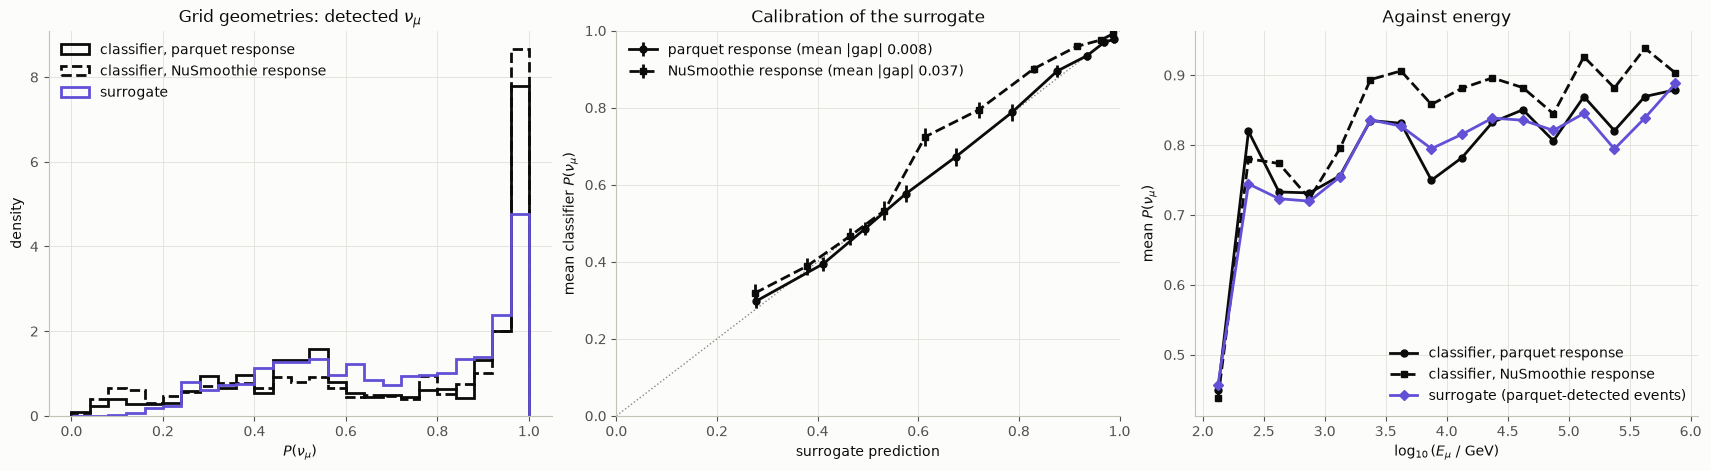

In [20]:
r = res[res.kind == 'grid']
det = r.p_mc.notna().to_numpy()
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6), constrained_layout=True)

ax = axes[0]
bins = np.linspace(0.0, 1.0, 26)
ax.hist(r.p_mc[det], bins=bins, density=True, histtype='step', lw=2, color=INK,
        label='classifier, parquet response')
ax.hist(r.p_sim.dropna(), bins=bins, density=True, histtype='step', lw=2, ls='--', color=INK,
        label='classifier, NuSmoothie response')
ax.hist(r.p_sur[det], bins=bins, density=True, histtype='step', lw=2, color=SUR_COLOR,
        label='surrogate')
ax.set(xlabel=r'$P(\nu_\mu)$', ylabel='density',
       title=r'Grid geometries: detected $\nu_\mu$')
ax.legend(loc='upper left')

ax = axes[1]
ax.plot([0.0, 1.0], [0.0, 1.0], color=MUTED, lw=1, ls=':')
for col, ls, mk, lab in (('p_mc', '-', 'o', 'parquet response'),
                         ('p_sim', '--', 's', 'NuSmoothie response')):
    mx, my, sem, err = calibration(r.p_sur.to_numpy(), r[col].to_numpy())
    ax.errorbar(mx, my, yerr=sem, color=INK, ls=ls, marker=mk, ms=5,
                label=f'{lab} (mean |gap| {err:.3f})')
ax.set(xlim=(0.0, 1.0), ylim=(0.0, 1.0), xlabel='surrogate prediction',
       ylabel=r'mean classifier $P(\nu_\mu)$', title='Calibration of the surrogate')
ax.legend(loc='upper left')

ax = axes[2]
edges = np.linspace(2.0, 6.0, 17)
centers = 0.5 * (edges[:-1] + edges[1:])
le = r.log10_e.to_numpy()
ax.plot(centers, binned_mean(le, r.p_mc.to_numpy(), edges), color=INK, marker='o', ms=5,
        label='classifier, parquet response')
ax.plot(centers, binned_mean(le, r.p_sim.to_numpy(), edges), color=INK, ls='--', marker='s',
        ms=5, label='classifier, NuSmoothie response')
ax.plot(centers, binned_mean(le, np.where(det, r.p_sur, np.nan), edges), color=SUR_COLOR,
        marker='D', ms=5, label='surrogate (parquet-detected events)')
ax.set(xlabel=r'$\log_{10}(E_\mu$ / GeV)', ylabel=r'mean $P(\nu_\mu)$', title='Against energy')
ax.legend(loc='lower right')
plt.show()

### Off the grid

NuSmoothie responses only. Both the classifier and the surrogate learned from grid geometries, so
agreement here shows that the surrogate follows the classifier off the grid, not that either is
right there.

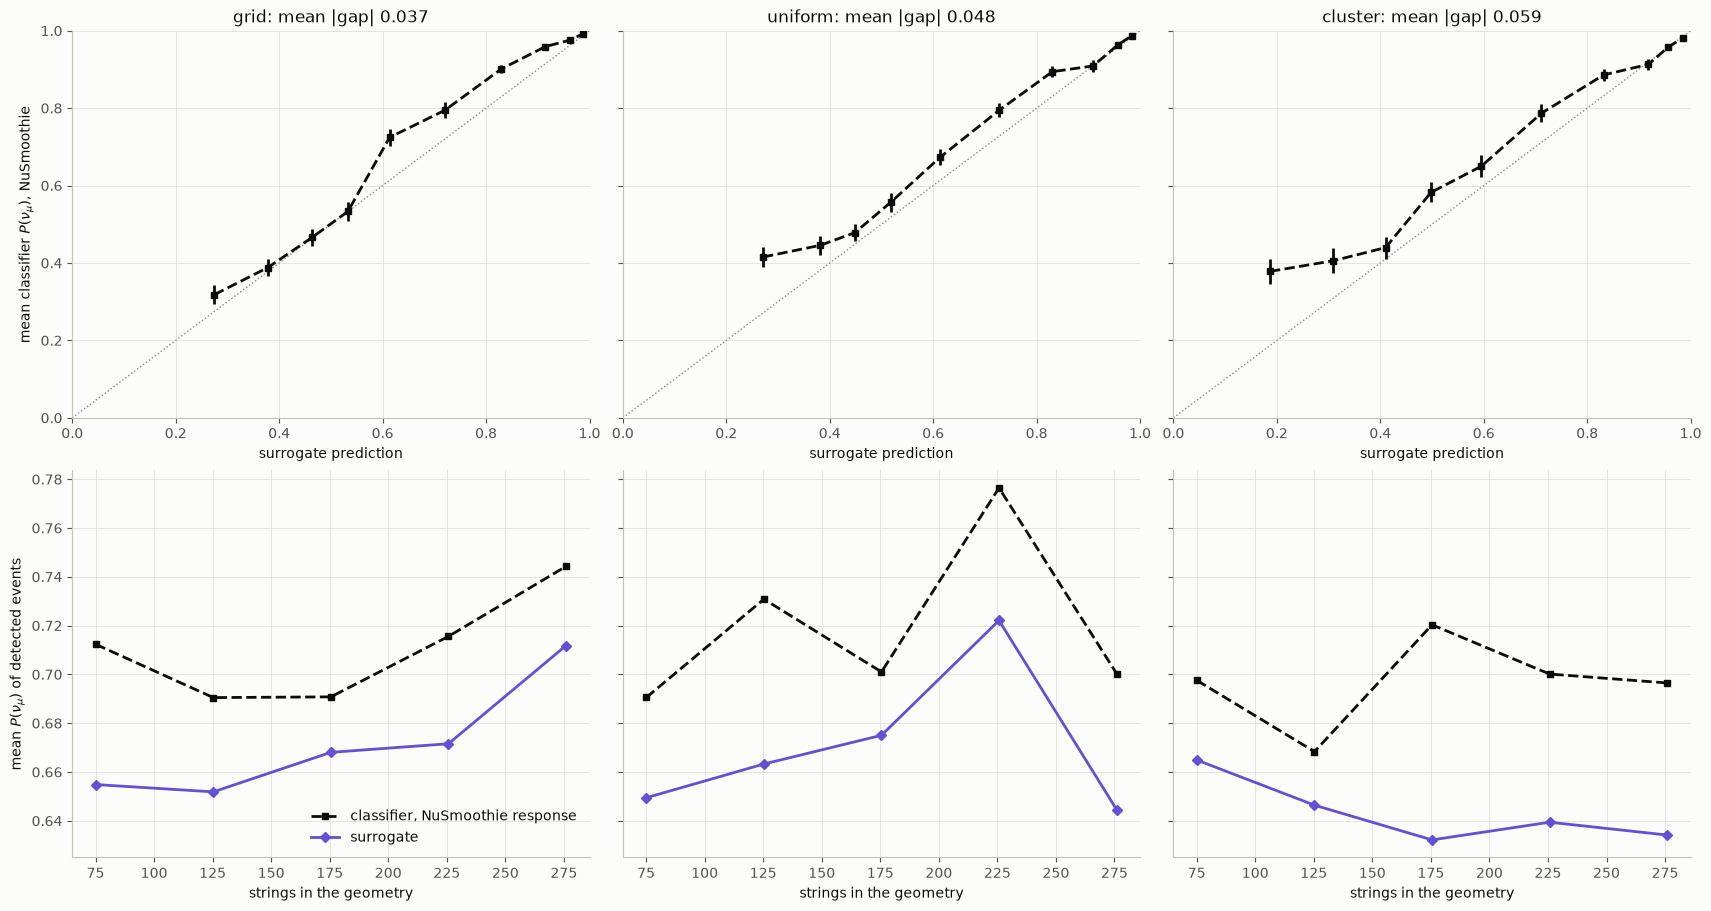

In [21]:
fig, axes = plt.subplots(2, len(LAYOUTS), figsize=(17, 9), sharey='row', constrained_layout=True)
s_edges = np.linspace(SUR_STRINGS[0], SUR_STRINGS[1] + 1, 6)
s_centers = 0.5 * (s_edges[:-1] + s_edges[1:])
for j, k in enumerate(LAYOUTS):
    r = res[res.kind == k]
    det = r.p_sim.notna().to_numpy()
    ax = axes[0, j]
    ax.plot([0.0, 1.0], [0.0, 1.0], color=MUTED, lw=1, ls=':')
    mx, my, sem, err = calibration(r.p_sur.to_numpy(), r.p_sim.to_numpy())
    ax.errorbar(mx, my, yerr=sem, color=INK, ls='--', marker='s', ms=5)
    ax.set(xlim=(0.0, 1.0), ylim=(0.0, 1.0), xlabel='surrogate prediction',
           title=f'{k}: mean |gap| {err:.3f}')
    ax = axes[1, j]
    ns = r.n_strings.to_numpy()
    ax.plot(s_centers, binned_mean(ns, r.p_sim.to_numpy(), s_edges), color=INK, ls='--',
            marker='s', ms=5, label='classifier, NuSmoothie response')
    ax.plot(s_centers, binned_mean(ns, np.where(det, r.p_sur, np.nan), s_edges),
            color=SUR_COLOR, marker='D', ms=5, label='surrogate')
    ax.set(xlabel='strings in the geometry')
axes[0, 0].set_ylabel(r'mean classifier $P(\nu_\mu)$, NuSmoothie')
axes[1, 0].set_ylabel(r'mean $P(\nu_\mu)$ of detected events')
axes[1, 0].legend(loc='lower right')
plt.show()

### Repeated responses of one event in one geometry

The surrogate's prediction for one (event, geometry) is an expectation over that event's possible
responses. NuSmoothie can draw many responses of the same event in the same geometry, which the
parquet cannot: `N_DRAWS` per pair, and the classifier's mean over the detected ones against the
surrogate. Pairs with fewer than 4 detected responses are redrawn. The RMS difference includes
the noise of the mean over `N_DRAWS` responses, shown next to it.

In [22]:
def repeated(kind, n_pairs, n_draws, seed, min_detected=4):
    """n_pairs (geometry, event) pairs, each with n_draws NuSmoothie responses: the classifier's
    mean P over the detected ones and its standard error, and the surrogate's prediction."""
    rng = np.random.default_rng(seed)
    mu._rng = rng
    out = []
    for _ in range(3 * n_pairs):
        if len(out) == n_pairs:
            break
        n = int(rng.integers(SUR_STRINGS[0], SUR_STRINGS[1] + 1))
        pos, _ = LAYOUTS[kind](n, rng)
        e = mu._sample_events(1)
        p = nusmoothie_p(pos, np.repeat(e, n_draws), rng)
        p = p[np.isfinite(p)]
        if len(p) >= min_detected:
            out.append(dict(kind=kind, n_strings=n, event=int(e[0]), n_detected=len(p),
                            p_sur=float(surrogate_p(pos, e)[0]), p_mean=p.mean(),
                            p_sem=p.std(ddof=1) / np.sqrt(len(p))))
    return pd.DataFrame(out)


t0 = time.time()
rep = pd.concat([repeated(k, N_PAIRS, N_DRAWS, seed=20 + i) for i, k in enumerate(LAYOUTS)],
                ignore_index=True)
print(f"{len(rep)} pairs x {N_DRAWS} NuSmoothie responses in {time.time() - t0:.0f} s")

180 pairs x 16 NuSmoothie responses in 497 s


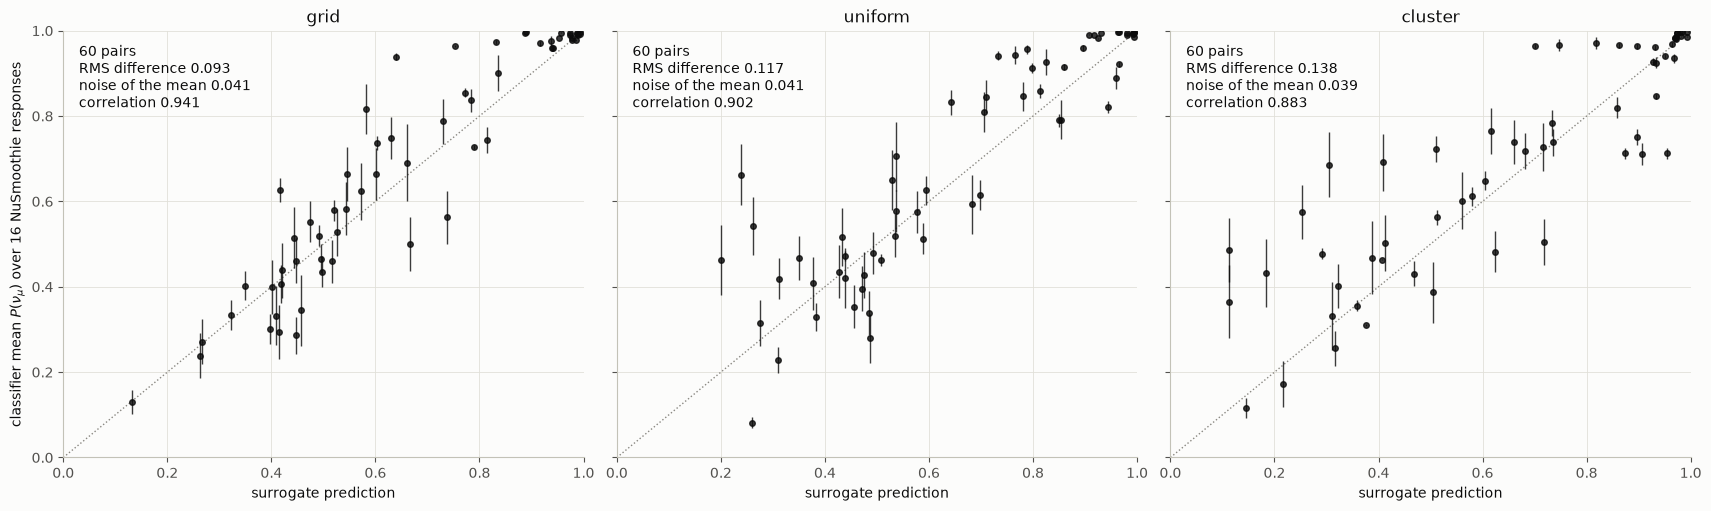

In [23]:
fig, axes = plt.subplots(1, len(LAYOUTS), figsize=(17, 5), sharey=True, constrained_layout=True)
for ax, k in zip(axes, LAYOUTS):
    r = rep[rep.kind == k]
    ax.plot([0.0, 1.0], [0.0, 1.0], color=MUTED, lw=1, ls=':')
    ax.errorbar(r.p_sur, r.p_mean, yerr=r.p_sem, ls='', marker='o', ms=4, color=INK,
                elinewidth=1, alpha=0.8)
    if len(r) > 1:
        rms = np.sqrt(np.mean((r.p_mean - r.p_sur) ** 2))
        noise = np.sqrt(np.mean(r.p_sem ** 2))
        ax.text(0.03, 0.97, f"{len(r)} pairs\nRMS difference {rms:.3f}\n"
                            f"noise of the mean {noise:.3f}\n"
                            f"correlation {np.corrcoef(r.p_sur, r.p_mean)[0, 1]:.3f}",
                transform=ax.transAxes, va='top')
    ax.set(xlim=(0.0, 1.0), ylim=(0.0, 1.0), xlabel='surrogate prediction', title=k)
axes[0].set_ylabel(fr'classifier mean $P(\nu_\mu)$ over {N_DRAWS} NuSmoothie responses')
plt.show()